# 03 · Train the hazard U-Net and test it fairly

**Milestone 3 of the Lunar Hazard Map.** The U-Net looks at NASA's 20 m maps (6 layers, 128 × 128) and guesses the safe / caution / no-go class of every 5 m pixel (512 × 512). It learns from the 2,234 training patches made in notebook 02, and it is then graded on test areas it has never seen.

**The question this notebook answers:** does the U-Net find no-go ground that the plain 20 m slope rule misses, *without just raising more false alarms*? Notebook 02 measured that the 25° rule on the 20 m map catches only 39% of 5 m no-go pixels in "mostly drivable" terrain (test split: 38%). Two things could make that gap smaller than it looks, and this notebook checks both:

1. **Some 5 m "no-go" pixels may be map noise, not real cliffs.** About 93% of 5 m pixels are filled in between laser tracks (measured in notebook 01). Section A checks how many no-go pixels are lone specks, and the test is scored twice: on every no-go pixel, and only on no-go patches big enough to matter to a rover.
2. **A lower cutoff would also catch more.** Dropping the rule from 25° to, say, 18° would raise its recall too. So the U-Net is compared to the slope rule at *every* cutoff (a precision–recall curve), and at the *same false-alarm level* as the 25° rule.

**Run time:** Section A about 1–2 min. Training about 30–60 min on the M2's GPU (estimated; the notebook prints the real time per round). Keep the laptop plugged in with the lid open. Training saves after every round, so if it stops, re-running the cell continues where it left off.

**Number labels.** *Sourced* = from a cited page or paper. *Placeholder* = a setting we picked that still has to be confirmed. *Setting* = a training choice, not a fact about the Moon. *Measured* = computed here from the data.


**Data citations:** Barker et al. 2023, *Planet. Sci. J.* 4, 183, doi:10.3847/PSJ/acf3e1 (20 m maps). Barker et al. 2021, *Planet. Space Sci.* 203, 105119, doi:10.1016/j.pss.2020.105119 (5 m mosaic).

## Setup

In [1]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # run any op MPS lacks on the CPU instead of crashing
import json, time, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage
import torch
import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp

plt.rcParams.update({"figure.dpi": 110, "image.origin": "upper"})
pd.set_option("display.width", 180)
print("torch", torch.__version__, "| smp", smp.__version__)

torch 2.10.0 | smp 0.5.0


In [2]:
# ---------------- Settings ----------------
DATA = Path(os.environ.get("LUNAR_DATA", Path.home() / "lunar" / "data"))
PATCHES = DATA / "patches"
MODELS = DATA / "models"                     # checkpoints live outside git
FIG = Path("figures"); RESULTS = Path("results")
for d in (MODELS, FIG, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

QUICK = os.environ.get("LUNAR_QUICK", "0") == "1"   # tiny smoke test, not a real result

# From notebook 02 (results/m2_summary.json), so the two notebooks always agree
M2 = json.loads((RESULTS / "m2_summary.json").read_text())
SAFE_MAX_DEG = M2["settings"]["safe_max_deg"]["value"]    # 15, SOURCED: NASA VIPER page
NOGO_MIN_DEG = M2["settings"]["nogo_min_deg"]["value"]    # 25, PLACEHOLDER: project plan
STRATA = [tuple(s) for s in M2["settings"]["strata"]]     # PLACEHOLDER terrain bins from notebook 02
CHANNELS = M2["settings"]["channels"]
CH_MEAN = np.array(M2["for_milestone_3"]["channel_mean"], "float32")[:, None, None]
CH_STD = np.array(M2["for_milestone_3"]["channel_std"], "float32")[:, None, None]
CLASS_W = np.array(M2["for_milestone_3"]["class_weights"], "float32")  # inverse class frequency, train split

# Label check
MIN_BLOB_PX = 4          # PLACEHOLDER: a no-go patch must cover >= 4 touching 5 m pixels (100 m2) to count as
                         # a rover-scale hazard in the "big patches only" score. Change once the rover size is known.

# Training (settings, not facts)
ENCODER = "resnet34"                       # same family as the landslide project
ENCODER_WEIGHTS = os.environ.get("LUNAR_ENC_WEIGHTS", "none" if QUICK else "imagenet")
HEAD_CH = 16                               # feature maps carried up from 20 m to 5 m
CLASS_W_POWER = 0.5                        # sqrt of inverse frequency: no-go still counts ~6x more than safe, without
                                           # the full 38x swing that makes the model paint everything red
EPOCHS = 2 if QUICK else 30
PATIENCE = 6                               # stop if val score hasn't improved for this many rounds
BATCH = 4 if QUICK else 8
LR, WEIGHT_DECAY = 3e-4, 1e-4
SEED = 23
FORCE_RETRAIN = False                      # True = ignore saved checkpoints and start over

# Fair-comparison settings
NB_NET, NB_RULE = 1000, 900                # score bins: U-Net prob in 0.001 steps, slope in 0.1 deg steps
WIN_MARGIN = 0.05                          # PLACEHOLDER: "clearly beats" = at least 0.05 better on both checks

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")
torch.manual_seed(SEED); rng = np.random.default_rng(SEED)

idx = pd.read_csv(PATCHES / "index.csv")
if QUICK:
    idx = pd.concat([g.head({"train": 40, "val": 16, "test": 12}[s]) for s, g in idx.groupby("split")])
TERRAINS = [s[2] for s in STRATA]
print("Device:", DEVICE, "| quick test mode" if QUICK else "")
print("Patches:", idx.split.value_counts().to_dict())
print(f"Thresholds: safe < {SAFE_MAX_DEG} deg, no-go >= {NOGO_MIN_DEG} deg")
print("Class weights used (sqrt of inverse frequency, setting):",
      dict(zip(["safe", "caution", "no-go"], (CLASS_W ** CLASS_W_POWER).round(2))))

Device: mps 
Patches: {'train': 2234, 'test': 599, 'val': 397}
Thresholds: safe < 15.0 deg, no-go >= 25.0 deg
Class weights used (sqrt of inverse frequency, setting): {'safe': np.float32(0.65), 'caution': np.float32(1.31), 'no-go': np.float32(4.03)}


In [3]:
# ---------------- Helpers ----------------
NODATA = 255
CLASS_CMAP = ListedColormap(["#2e9e5b", "#f0b429", "#d64545"])
EIGHT = np.ones((3, 3), bool)

def load_patch(pid):
    z = np.load(PATCHES / f"{pid}.npz")
    x = z["x"].astype("float32"); y = z["y"]
    real = np.unpackbits(z["real"])[: y.size].reshape(y.shape).astype(bool)
    return x, y, real

def normalise(x):
    return np.nan_to_num((x - CH_MEAN) / CH_STD, nan=0.0).astype("float32")

def up4(a):
    return np.repeat(np.repeat(a, 4, 0), 4, 1)

def small_blobs(nogo):
    # no-go pixels that sit in a touching group smaller than MIN_BLOB_PX (8-neighbour)
    lab, n = ndimage.label(nogo, structure=EIGHT)
    if n == 0:
        return np.zeros_like(nogo)
    sizes = np.bincount(lab.ravel()); sizes[0] = 0
    return (sizes < MIN_BLOB_PX)[lab] & nogo

def pr_curve(pos, neg):
    # pos/neg: counts per score bin (low -> high). Sweep the cutoff from high to low.
    tp = np.cumsum(pos[::-1]).astype("float64"); fp = np.cumsum(neg[::-1]).astype("float64")
    rec = tp / max(pos.sum(), 1)
    prec = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 1.0)
    return rec, prec

def avg_precision(rec, prec):
    return float(np.sum(np.diff(np.concatenate([[0.0], rec])) * prec))

def recall_at(rec, prec, p0):
    ok = prec >= p0 - 1e-12
    return float(rec[ok].max()) if ok.any() else 0.0

def prf(tp, fp, fn):
    r = tp / (tp + fn) if tp + fn else np.nan
    p = tp / (tp + fp) if tp + fp else np.nan
    return r, p, (2 * p * r / (p + r) if p + r > 0 else np.nan)

## A · Are the 5 m "no-go" pixels real hazards or map noise?

**Plain English.** The answer key comes from the 5 m map, and most of that map is filled in between laser tracks. Filling in can leave small bumps that look steep at 5 m but aren't real. If a lot of the no-go ground on flat terrain is single, isolated pixels, some of the 20 m rule's "misses" are probably not cliffs at all. This counts them.

Two checks, per terrain type, over all 3,230 patches:

- **Isolated specks:** share of no-go pixels in a touching group smaller than `MIN_BLOB_PX` (placeholder: 4 pixels = 100 m²).
- **Real vs filled-in:** how often a pixel is no-go where LOLA actually has a shot, versus where the map was filled in. A big difference points to map artifacts. (This is a hint, not proof: shot pixels are not a random sample of the ground.)

It also loads the train and val patches into memory for training (about 1.2 GB).

In [4]:
audit = []
keep = {"train": [], "val": []}
t0 = time.time()
for n, r in enumerate(idx.itertuples()):
    x, y, real = load_patch(r.id)
    v = y != NODATA
    nogo = (y == 2)
    sb = small_blobs(nogo)
    audit.append(dict(id=r.id, split=r.split, terrain=r.terrain, valid=int(v.sum()), nogo=int(nogo.sum()),
                      nogo_small=int(sb.sum()), real=int((v & real).sum()), nogo_real=int((nogo & real).sum()),
                      interp=int((v & ~real).sum()), nogo_interp=int((nogo & ~real).sum())))
    if r.split in keep:
        keep[r.split].append((x.astype("float16"), y))
    if (n + 1) % 500 == 0 or n + 1 == len(idx):
        print(f"\r  {n + 1:,}/{len(idx):,} patches, {time.time() - t0:.0f} s", end="", flush=True)
print()
A = pd.DataFrame(audit)

def audit_table(g):
    return pd.Series(dict(
        **{"patches": len(g),
           "no-go share": g.nogo.sum() / g.valid.sum(),
           "speck share of no-go": g.nogo_small.sum() / max(g.nogo.sum(), 1),
           "no-go at shot px": g.nogo_real.sum() / max(g.real.sum(), 1),
           "no-go at filled px": g.nogo_interp.sum() / max(g.interp.sum(), 1)},
    ))
A_tab = pd.DataFrame({t: audit_table(A[A.terrain == t]) for t in TERRAINS if (A.terrain == t).any()}
                     | {"all": audit_table(A)}).T
print(f"Label check (measured). Isolated speck = no-go group smaller than {MIN_BLOB_PX} px:")
display(A_tab.round(3))

Xtr = np.stack([k[0] for k in keep["train"]]); Ytr = np.stack([k[1] for k in keep["train"]])
Xva = np.stack([k[0] for k in keep["val"]]); Yva = np.stack([k[1] for k in keep["val"]])
del keep
va_terrain = idx[idx.split == "val"].terrain.to_numpy()
print(f"In memory: train {Xtr.shape[0]} and val {Xva.shape[0]} patches, "
      f"{(Xtr.nbytes + Ytr.nbytes + Xva.nbytes + Yva.nbytes) / 1e9:.2f} GB")

  500/3,230 patches, 2 s

  1,000/3,230 patches, 4 s

  1,500/3,230 patches, 6 s

  2,000/3,230 patches, 8 s

  2,500/3,230 patches, 10 s

  3,000/3,230 patches, 12 s

  3,230/3,230 patches, 13 s


Label check (measured). Isolated speck = no-go group smaller than 4 px:


,patches,no-go share,speck share of no-go,no-go at shot px,no-go at filled px
mostly drivable,3032.0,0.005,0.106,0.006,0.005
mixed,130.0,0.226,0.013,0.217,0.226
mostly steep,68.0,0.818,0.001,0.817,0.818
all,3230.0,0.031,0.021,0.033,0.031


In memory: train 2234 and val 397 patches, 1.21 GB


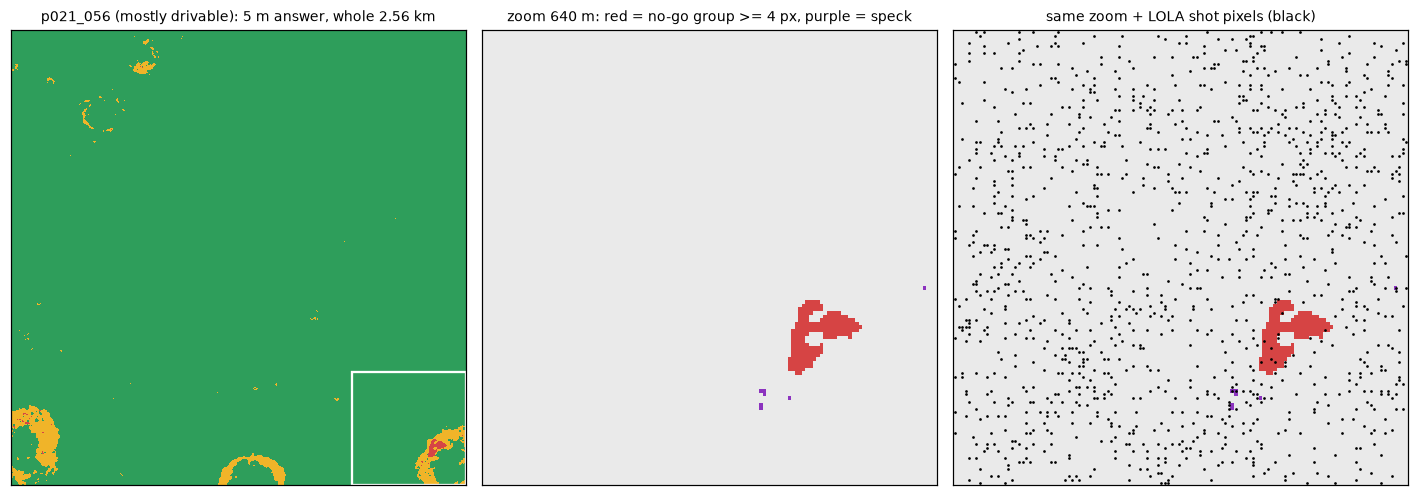

In [5]:
# Look closely at one drivable test patch: where are the no-go pixels, and where are the laser shots?
cand = A[(A.split == "test") & (A.terrain == TERRAINS[0])].sort_values("nogo")
if len(cand):
    pid = cand.iloc[len(cand) // 2].id                      # a typical one, not the worst
    x, y, real = load_patch(pid)
    nogo = y == 2; sb = small_blobs(nogo)
    # zoom on the 640 m square with the most no-go pixels
    k = 128
    sums = nogo.reshape(4, k, 4, k).sum(axis=(1, 3))
    bi, bj = np.unravel_index(sums.argmax(), sums.shape)
    sl = (slice(bi * k, bi * k + k), slice(bj * k, bj * k + k))
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
    ax[0].imshow(np.ma.masked_equal(y, NODATA), cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5, interpolation="nearest")
    ax[0].add_patch(plt.Rectangle((bj * k, bi * k), k, k, fill=False, ec="white", lw=1.5))
    ax[0].set_title(f"{pid} ({TERRAINS[0]}): 5 m answer, whole 2.56 km", fontsize=9)
    rgb = np.zeros((k, k, 3)) + 0.92
    rgb[nogo[sl] & ~sb[sl]] = (0.84, 0.27, 0.27)          # big no-go groups: red
    rgb[sb[sl]] = (0.55, 0.2, 0.75)                      # isolated specks: purple
    ax[1].imshow(rgb, interpolation="nearest")
    ax[1].set_title(f"zoom 640 m: red = no-go group >= {MIN_BLOB_PX} px, purple = speck", fontsize=9)
    ax[2].imshow(rgb, interpolation="nearest")
    ry, rx = np.nonzero(real[sl]); ax[2].scatter(rx, ry, s=0.6, c="k")
    ax[2].set_title("same zoom + LOLA shot pixels (black)", fontsize=9)
    for a in ax: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.savefig(FIG / "M3_label_check.png", dpi=150); plt.show()

**How to read this.** If the "speck share of no-go" for mostly drivable ground is high (say over a third), the 20 m rule's 39% recall on raw pixels understates it, and the **"big patches only"** scores in Section D are the fairer target. If no-go is much more common at filled-in pixels than at shot pixels, that also points to filling-in artifacts. If no-go specks line up in stripes along the black shot tracks, they are likely track-to-track mismatches in the map.

## B · The model

**Plain English.** A standard U-Net (the same kind as the landslide detector) reads the 20 m layers and builds a 16-layer description of each 20 m pixel. That is then stretched 4× to the 5 m grid, and two small layers turn it into safe / caution / no-go for each 5 m pixel. The model can't see anything smaller than 20 m directly. What it can learn is which 20 m patterns (bumps, slope changes, shadow, crater rims) tend to hide steep 5 m ground.

**Technical.** `smp.Unet(resnet34, in_channels=6, classes=16)` at 128 × 128 → bilinear ×4 → Conv3×3–BN–ReLU ×2 → Conv1×1 → 3 classes at 512 × 512. Loss = weighted cross-entropy + Dice (same as the landslide project), with NoData pixels ignored. Inputs are scaled with the train-only mean and spread from notebook 02. Training adds random 90° turns and mirror flips (applied to inputs and answer together). AdamW with a cosine learning-rate schedule. The kept checkpoint is the round with the best **val average precision for no-go on mostly drivable ground** (explained in Section D), because that's the terrain rovers drive on.

In [6]:
class HazardNet(nn.Module):
    def __init__(self, weights):
        super().__init__()
        self.unet = smp.Unet(ENCODER, encoder_weights=weights, in_channels=len(CHANNELS), classes=HEAD_CH)
        self.head = nn.Sequential(
            nn.Conv2d(HEAD_CH, HEAD_CH, 3, padding=1), nn.BatchNorm2d(HEAD_CH), nn.ReLU(inplace=True),
            nn.Conv2d(HEAD_CH, HEAD_CH, 3, padding=1), nn.BatchNorm2d(HEAD_CH), nn.ReLU(inplace=True),
            nn.Conv2d(HEAD_CH, 3, 1))
    def forward(self, x):
        f = self.unet(x)
        f = F.interpolate(f, scale_factor=4, mode="bilinear", align_corners=False)
        return self.head(f)

def make_model():
    w = None if ENCODER_WEIGHTS.lower() == "none" else ENCODER_WEIGHTS
    try:
        return HazardNet(w), w
    except Exception as e:   # no internet for the pretrained weights -> start from scratch, and say so
        print(f"Could not load '{w}' weights ({type(e).__name__}); starting from random weights instead.")
        return HazardNet(None), None

model, used_weights = make_model()
model = model.to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"HazardNet: {n_params / 1e6:.1f} M parameters, encoder {ENCODER} ({used_weights or 'random init'})")

with torch.no_grad():
    out = model(torch.zeros(2, len(CHANNELS), 128, 128, device=DEVICE))
print("Shape check: input (2, 6, 128, 128) ->", tuple(out.shape))

cw = torch.tensor(CLASS_W ** CLASS_W_POWER, device=DEVICE)
ce = nn.CrossEntropyLoss(weight=cw, ignore_index=NODATA)
dice = smp.losses.DiceLoss(mode="multiclass", ignore_index=NODATA, from_logits=True)
def loss_fn(logits, y):
    return ce(logits, y) + dice(logits, y)

def augment(x, y):
    k = rng.integers(4)
    x = np.rot90(x, k, axes=(1, 2)); y = np.rot90(y, k, axes=(0, 1))
    if rng.random() < 0.5:
        x = x[:, :, ::-1]; y = y[:, ::-1]
    return np.ascontiguousarray(x), np.ascontiguousarray(y)

def to_dev(xb, yb):
    return (torch.from_numpy(np.stack(xb)).to(DEVICE),
            torch.from_numpy(np.stack(yb).astype("int64")).to(DEVICE))

@torch.no_grad()
def predict(xs):
    # xs: list of raw (6,128,128) arrays -> (no-go probability, class) at 512 x 512 each
    model.eval()
    xb = torch.from_numpy(np.stack([normalise(x) for x in xs])).to(DEVICE)
    p = torch.softmax(model(xb), 1)
    return p[:, 2].float().cpu().numpy(), p.argmax(1).to(torch.uint8).cpu().numpy()

HazardNet: 24.5 M parameters, encoder resnet34 (imagenet)


Shape check: input (2, 6, 128, 128) -> (2, 3, 512, 512)


## C · Train

**Plain English.** One "round" (epoch) = the model sees every training patch once. After each round it's graded on the val patches. The best round is saved, and training stops early if val stops improving for 6 rounds.

Checkpoints go to `~/lunar/data/models/`. If the laptop sleeps or you stop the cell, just run it again: it picks up from the last finished round. Once training has finished, re-running the notebook skips straight to grading.

In [7]:
def nogo_hist(prob, y, mask):
    b = np.clip((prob * NB_NET).astype(np.int32), 0, NB_NET - 1)
    pos = (y == 2) & mask; neg = (y != 2) & mask
    return np.bincount(b[pos], minlength=NB_NET), np.bincount(b[neg], minlength=NB_NET)

@torch.no_grad()
def evaluate_val():
    model.eval()
    tot, nb = 0.0, 0
    h = {t: [np.zeros(NB_NET), np.zeros(NB_NET)] for t in ["all"] + TERRAINS}
    for s in range(0, len(Xva), BATCH):
        xb = [normalise(x.astype("float32")) for x in Xva[s:s + BATCH]]
        yb = list(Yva[s:s + BATCH])
        X, Y = to_dev(xb, yb)
        logits = model(X)
        tot += loss_fn(logits, Y).item(); nb += 1
        prob = torch.softmax(logits, 1)[:, 2].float().cpu().numpy()
        for k in range(len(yb)):
            m = yb[k] != NODATA
            ph, nh = nogo_hist(prob[k], yb[k], m)
            for t in ("all", va_terrain[s + k]):
                h[t][0] += ph; h[t][1] += nh
    ap = {t: avg_precision(*pr_curve(*h[t])) if h[t][0].sum() else np.nan for t in h}
    return tot / max(nb, 1), ap

ckpt_last, ckpt_best = MODELS / "hazard_unet_last.pt", MODELS / "hazard_unet_best.pt"
config = dict(encoder=ENCODER, weights=str(used_weights), head_ch=HEAD_CH, class_w_power=CLASS_W_POWER,
              lr=LR, batch=BATCH, epochs=EPOCHS, quick=QUICK, n_train=len(Xtr))
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
start, best, best_epoch, history, done = 0, -1.0, -1, [], False

if ckpt_last.exists() and not FORCE_RETRAIN:
    c = torch.load(ckpt_last, map_location=DEVICE, weights_only=False)
    if c["config"] == config:
        model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"]); sched.load_state_dict(c["sched"])
        start, best, best_epoch, history, done = c["epoch"], c["best"], c["best_epoch"], c["history"], c["done"]
        print(f"Resuming after round {start} (best val score {best:.3f} at round {best_epoch}).")
    else:
        print("Saved checkpoint used different settings; starting over.")

TRAIN_KEY = TERRAINS[0]          # model selection: val AP for no-go on mostly drivable ground
n_tr = len(Xtr)
for epoch in range(start, EPOCHS):
    if done:
        break
    model.train(); t0 = time.time(); run, nb = 0.0, 0
    order = rng.permutation(n_tr)
    for s in range(0, n_tr - BATCH + 1, BATCH):
        xb, yb = [], []
        for i in order[s:s + BATCH]:
            x_, y_ = augment(normalise(Xtr[i].astype("float32")), Ytr[i])
            xb.append(x_); yb.append(y_)
        X, Y = to_dev(xb, yb)
        opt.zero_grad(set_to_none=True)
        loss = loss_fn(model(X), Y)
        loss.backward(); opt.step()
        run += loss.item(); nb += 1
    sched.step()
    vloss, vap = evaluate_val()
    score = vap[TRAIN_KEY] if np.isfinite(vap[TRAIN_KEY]) else vap["all"]
    history.append(dict(epoch=epoch + 1, train_loss=run / max(nb, 1), val_loss=vloss,
                        val_ap_all=vap["all"], **{f"val_ap_{t}": vap[t] for t in TERRAINS},
                        minutes=(time.time() - t0) / 60))
    improved = score > best
    if improved:
        best, best_epoch = score, epoch + 1
        torch.save(dict(model=model.state_dict(), config=config, epoch=epoch + 1, val_score=best), ckpt_best)
    done = (epoch + 1 - best_epoch) >= PATIENCE or epoch + 1 == EPOCHS
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), config=config,
                    epoch=epoch + 1, best=best, best_epoch=best_epoch, history=history, done=done), ckpt_last)
    print(f"round {epoch + 1:2d}/{EPOCHS}  train loss {history[-1]['train_loss']:.3f}  val loss {vloss:.3f}  "
          f"val no-go AP: all {vap['all']:.3f}, {TRAIN_KEY} {vap[TRAIN_KEY]:.3f}  "
          f"{'*saved*' if improved else ''}  ({history[-1]['minutes']:.1f} min)")
    if done and epoch + 1 < EPOCHS:
        print(f"Stopping early: no improvement for {PATIENCE} rounds.")

H = pd.DataFrame(history)
H.to_csv(RESULTS / "m3_history.csv", index=False)
c = torch.load(ckpt_best, map_location=DEVICE, weights_only=False)
model.load_state_dict(c["model"])
print(f"Using best round {c['epoch']} (val no-go AP on {TRAIN_KEY}: {c['val_score']:.3f}). "
      f"Total training time {H.minutes.sum():.0f} min.")
del Xtr, Ytr

round  1/30  train loss 1.208  val loss 1.028  val no-go AP: all 0.702, mostly drivable 0.349  *saved*  (2.5 min)


round  2/30  train loss 0.935  val loss 0.846  val no-go AP: all 0.750, mostly drivable 0.419  *saved*  (2.9 min)


round  3/30  train loss 0.850  val loss 0.716  val no-go AP: all 0.754, mostly drivable 0.436  *saved*  (2.9 min)


round  4/30  train loss 0.805  val loss 0.667  val no-go AP: all 0.747, mostly drivable 0.387    (2.9 min)


round  5/30  train loss 0.751  val loss 0.630  val no-go AP: all 0.740, mostly drivable 0.401    (2.9 min)


round  6/30  train loss 0.721  val loss 0.647  val no-go AP: all 0.743, mostly drivable 0.408    (2.9 min)


... (21 outputs left out)

round 28/30  train loss 0.483  val loss 0.499  val no-go AP: all 0.803, mostly drivable 0.505    (3.0 min)


round 29/30  train loss 0.480  val loss 0.500  val no-go AP: all 0.802, mostly drivable 0.499    (3.0 min)


round 30/30  train loss 0.486  val loss 0.503  val no-go AP: all 0.803, mostly drivable 0.500    (3.4 min)


Using best round 25 (val no-go AP on mostly drivable: 0.507). Total training time 88 min.


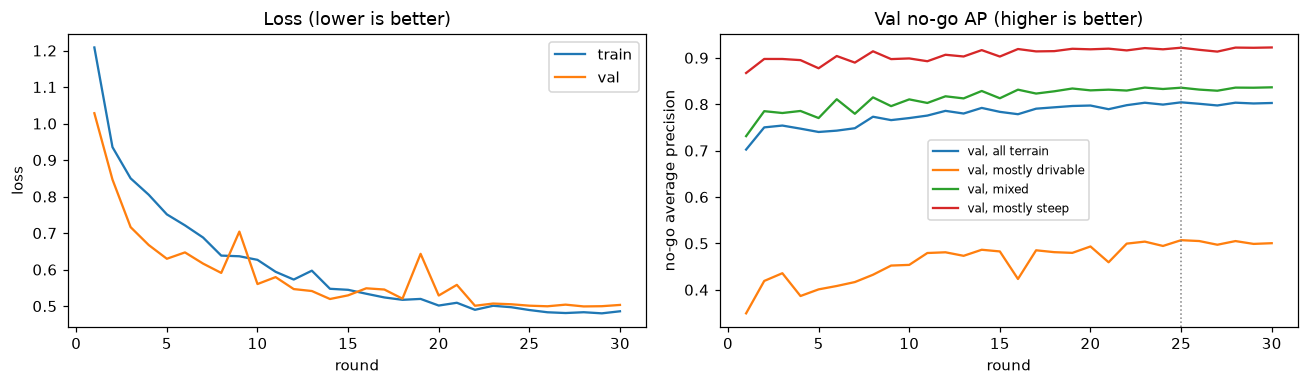

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(H.epoch, H.train_loss, label="train"); ax[0].plot(H.epoch, H.val_loss, label="val")
ax[0].set_xlabel("round"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss (lower is better)"); ax[0].legend()
ax[1].plot(H.epoch, H.val_ap_all, label="val, all terrain")
for t in TERRAINS:
    ax[1].plot(H.epoch, H[f"val_ap_{t}"], label=f"val, {t}")
ax[1].axvline(best_epoch, color="gray", ls=":", lw=1)
ax[1].set_xlabel("round"); ax[1].set_ylabel("no-go average precision"); ax[1].set_title("Val no-go AP (higher is better)")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "M3_training.png", dpi=150); plt.show()

## D · The fair test: U-Net vs the slope rule on unseen areas

**Plain English.** Any detector can catch more cliffs by crying wolf more often. So the test isn't "who catches more", it's "who catches more **for the same number of false alarms**".

- **Recall** = of the real no-go pixels, how many got flagged. Missing a cliff is the costly mistake.
- **Precision** = of the flagged pixels, how many really are no-go. Low precision means routes get blocked for no reason.
- Slide the slope rule's cutoff from 90° down to 0°, and the U-Net's confidence cutoff from 1 down to 0, and you get a **precision–recall curve** for each. **Average precision (AP)** is the area under that curve: one number for the whole trade-off, 1.0 is perfect.
- **Recall at matched precision** = set each method's cutoff so it's exactly as precise as today's 25° rule, then see how many no-go pixels each one catches.

One small handicap for the U-Net: it sees each 2.56 km patch on its own, so it is a bit less sure near patch edges. Notebook 04 fixes that with overlapping windows, so these scores are, if anything, slightly low for the U-Net.

Scored on the **test** areas only, by terrain type, and in two versions: **every no-go pixel** ("raw") and **big no-go patches only** (groups of at least `MIN_BLOB_PX` pixels; isolated specks are left out of the score, not counted as safe). Each is also scored on LOLA-shot pixels only, where the 5 m answer is measured rather than filled in.

In [9]:
BLOB = f"big patches (>= {MIN_BLOB_PX} px)"
LABELSETS = ["raw", BLOB]
SUBSETS = ["all px", "LOLA-shot px"]
def new_acc():
    return dict(np_=np.zeros(NB_NET), nn_=np.zeros(NB_NET), rp=np.zeros(NB_RULE), rn=np.zeros(NB_RULE),
                rule=np.zeros(3), net=np.zeros(3), patches=0)
ACC = {}
test = idx[idx.split == "test"].reset_index(drop=True)
t0 = time.time()
for s in range(0, len(test), BATCH):
    rows = test.iloc[s:s + BATCH]
    loaded = [load_patch(pid) for pid in rows.id]
    prob, cls = predict([l[0] for l in loaded])
    for k, (r, (x, y, real)) in enumerate(zip(rows.itertuples(), loaded)):
        s20 = up4(x[1])                                         # raw 20 m slope (deg) on the 5 m grid
        valid = (y != NODATA) & np.isfinite(s20)
        nogo = y == 2
        speck = small_blobs(nogo)
        bn = np.clip((prob[k] * NB_NET).astype(np.int32), 0, NB_NET - 1)
        br = np.clip((np.nan_to_num(s20) * 10).astype(np.int32), 0, NB_RULE - 1)
        rule_flag = s20 >= NOGO_MIN_DEG; net_flag = cls[k] == 2
        groups = ["all", r.terrain] + (["M1 Shackleton window"] if r.in_m1 else [])
        for lab, m0 in (("raw", valid), (BLOB, valid & ~speck)):
            for sub, m in (("all px", m0), ("LOLA-shot px", m0 & real)):
                pos, neg = nogo & m, ~nogo & m
                parts = dict(np_=np.bincount(bn[pos], minlength=NB_NET), nn_=np.bincount(bn[neg], minlength=NB_NET),
                             rp=np.bincount(br[pos], minlength=NB_RULE), rn=np.bincount(br[neg], minlength=NB_RULE),
                             rule=np.array([(pos & rule_flag).sum(), (neg & rule_flag).sum(), (pos & ~rule_flag).sum()]),
                             net=np.array([(pos & net_flag).sum(), (neg & net_flag).sum(), (pos & ~net_flag).sum()]))
                for g in groups:
                    a = ACC.setdefault((g, lab, sub), new_acc())
                    for key, v in parts.items():
                        a[key] += v
                    a["patches"] += 1
    print(f"\r  {min(s + BATCH, len(test)):,}/{len(test):,} test patches, {time.time() - t0:.0f} s", end="", flush=True)
print()

rows_out, curves = [], {}
for (g, lab, sub), a in ACC.items():
    rr, rp_ = pr_curve(a["rp"], a["rn"]); nr, np_ = pr_curve(a["np_"], a["nn_"])
    curves[(g, lab, sub)] = (rr, rp_, nr, np_)
    r_rec, r_prec, r_f1 = prf(*a["rule"]); n_rec, n_prec, n_f1 = prf(*a["net"])
    p0 = r_prec            # NaN when the 25 deg rule flags nothing -> no matched-precision score
    rows_out.append(dict(group=g, labels=lab, pixels=sub, patches=a["patches"] // 1,
                         truth_nogo_px=int(a["np_"].sum()),
                         rule25_recall=r_rec, rule25_precision=r_prec,
                         unet_recall=n_rec, unet_precision=n_prec,
                         ap_slope_rule=avg_precision(rr, rp_), ap_unet=avg_precision(nr, np_),
                         recall_at_rule25_precision_slope=recall_at(rr, rp_, p0) if np.isfinite(p0) else np.nan,
                         recall_at_rule25_precision_unet=recall_at(nr, np_, p0) if np.isfinite(p0) else np.nan))
D = pd.DataFrame(rows_out)
order = {g: i for i, g in enumerate(["all"] + TERRAINS + ["M1 Shackleton window"])}
porder = {"all px": 0, "LOLA-shot px": 1}
D = D.sort_values(["labels", "pixels", "group"],
                  key=lambda c: c.map(order) if c.name == "group" else c.map(porder) if c.name == "pixels" else c,
                  ascending=[False, True, True]).reset_index(drop=True)
D["ap_gain"] = D.ap_unet - D.ap_slope_rule
D["recall_gain_at_same_precision"] = D.recall_at_rule25_precision_unet - D.recall_at_rule25_precision_slope

# Narrow tables so they survive PDF export. All columns are also in results/m3_summary.json.
SHORT = {"group": "terrain", "pixels": "pixels", "truth_nogo_px": "no-go px", "ap_slope_rule": "AP rule",
         "ap_unet": "AP U-Net", "rule25_precision": "matched prec", "recall_at_rule25_precision_slope": "recall rule",
         "recall_at_rule25_precision_unet": "recall U-Net"}
for lab in LABELSETS:
    print(f"\nTEST, labels = {lab} (measured). AP = whole trade-off; recall = at the 25 deg rule's precision:")
    t = D[D.labels == lab][list(SHORT)].rename(columns=SHORT)
    display(t.round(3).reset_index(drop=True))
print("\nClass-map points (U-Net argmax vs 25 deg rule), test, all px (measured):")
pts = D[D.pixels == "all px"][["group", "labels", "rule25_recall", "rule25_precision", "unet_recall", "unet_precision"]]
display(pts.rename(columns={"group": "terrain", "rule25_recall": "rule rec", "rule25_precision": "rule prec",
                            "unet_recall": "U-Net rec", "unet_precision": "U-Net prec"}).round(3).reset_index(drop=True))

  8/599 test patches, 1 s

  16/599 test patches, 1 s

  24/599 test patches, 2 s

  32/599 test patches, 3 s

  40/599 test patches, 3 s

  48/599 test patches, 4 s

... (71 outputs left out)


TEST, labels = big patches (>= 4 px) (measured). AP = whole trade-off; recall = at the 25 deg rule's precision:


,terrain,pixels,no-go px,AP rule,AP U-Net,matched prec,recall rule,recall U-Net
0,all,all px,12756057,0.964,0.956,0.914,0.900,0.890
1,mostly drivable,all px,982908,0.562,0.560,0.683,0.426,0.394
2,mixed,all px,2417966,0.859,0.852,0.799,0.763,0.732
3,mostly steep,all px,9355183,0.990,0.980,0.956,0.985,0.977
4,M1 Shackleton window,all px,4201413,0.989,0.980,0.955,0.968,0.961
5,all,LOLA-shot px,1129264,0.959,0.948,0.911,0.900,0.891
6,mostly drivable,LOLA-shot px,76314,0.538,0.531,0.696,0.364,0.340
7,mixed,LOLA-shot px,198425,0.853,0.843,0.798,0.749,0.717
8,mostly steep,LOLA-shot px,854525,0.982,0.969,0.944,0.983,0.976
9,M1 Shackleton window,LOLA-shot px,355926,0.982,0.970,0.945,0.966,0.960



Class-map points (U-Net argmax vs 25 deg rule), test, all px (measured):


,terrain,labels,rule rec,rule prec,U-Net rec,U-Net prec
0,all,raw,0.890,0.914,0.924,0.866
1,mostly drivable,raw,0.385,0.683,0.480,0.574
2,mixed,raw,0.752,0.799,0.850,0.706
3,mostly steep,raw,0.984,0.956,0.995,0.940
4,M1 Shackleton window,raw,0.966,0.955,0.980,0.933
5,all,big patches (>= 4 px),0.900,0.914,0.934,0.866
6,mostly drivable,big patches (>= 4 px),0.426,0.683,0.530,0.574
7,mixed,big patches (>= 4 px),0.763,0.799,0.860,0.706
8,mostly steep,big patches (>= 4 px),0.985,0.956,0.995,0.940
9,M1 Shackleton window,big patches (>= 4 px),0.968,0.955,0.982,0.933


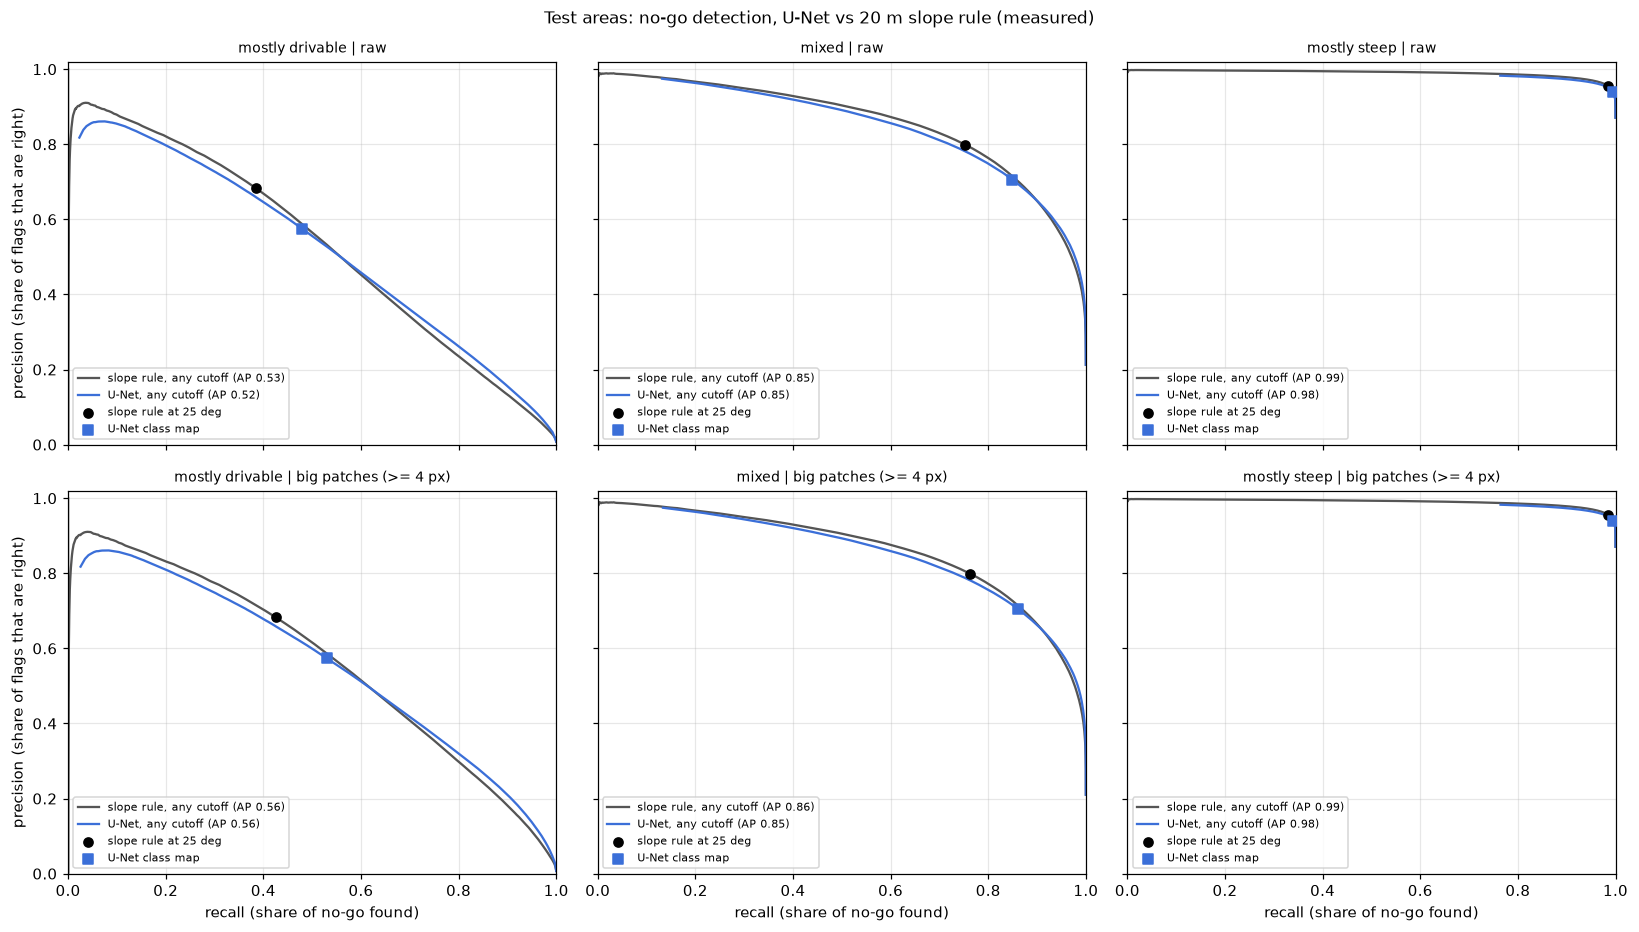

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.6), sharex=True, sharey=True)
for row, lab in enumerate(LABELSETS):
    for col, t in enumerate(TERRAINS):
        ax = axes[row, col]; key = (t, lab, "all px")
        if key not in curves:
            ax.set_title(f"{t}: no test patches"); continue
        rr, rp_, nr, np_ = curves[key]; d = D[(D.group == t) & (D.labels == lab) & (D.pixels == "all px")].iloc[0]
        ax.plot(rr, rp_, color="#555", label=f"slope rule, any cutoff (AP {d.ap_slope_rule:.2f})")
        ax.plot(nr, np_, color="#3b6fd8", label=f"U-Net, any cutoff (AP {d.ap_unet:.2f})")
        ax.scatter([d.rule25_recall], [d.rule25_precision], color="k", zorder=3, label="slope rule at 25 deg")
        ax.scatter([d.unet_recall], [d.unet_precision], color="#3b6fd8", marker="s", zorder=3, label="U-Net class map")
        ax.set_title(f"{t} | {lab}", fontsize=9); ax.legend(fontsize=7, loc="lower left")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
for a in axes[-1]: a.set_xlabel("recall (share of no-go found)")
for a in axes[:, 0]: a.set_ylabel("precision (share of flags that are right)")
fig.suptitle("Test areas: no-go detection, U-Net vs 20 m slope rule (measured)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "M3_pr_curves.png", dpi=150); plt.show()

**How to read the curves.** Up and to the right is better. If the blue curve sits above the gray one in "mostly drivable", the U-Net finds more hazards at the same false-alarm rate. The black dot is today's 25° rule; the gray curve through it shows what you'd get by just moving the cutoff.

In [11]:
def verdict_row(lab, sub="all px", g=TERRAINS[0]):
    d = D[(D.group == g) & (D.labels == lab) & (D.pixels == sub)]
    return None if d.empty else d.iloc[0]

lines, wins = [], []
for lab in LABELSETS:
    d = verdict_row(lab)
    if d is None:
        continue
    win = d.ap_gain >= WIN_MARGIN and d.recall_gain_at_same_precision >= WIN_MARGIN
    wins.append(win)
    lines.append(f"  {lab:>24}: AP {d.ap_slope_rule:.3f} -> {d.ap_unet:.3f} ({d.ap_gain:+.3f}); recall at the 25 deg "
                 f"rule's precision ({d.rule25_precision:.2f}) {d.recall_at_rule25_precision_slope:.3f} -> "
                 f"{d.recall_at_rule25_precision_unet:.3f} ({d.recall_gain_at_same_precision:+.3f})")
print(f"Mostly drivable test areas, slope rule -> U-Net (measured; 'clearly beats' = both gains >= {WIN_MARGIN}, placeholder):")
print("\n".join(lines))
if wins and all(wins):
    VERDICT = "U-Net clearly beats the tuned slope rule on drivable ground, on both label versions."
elif any(wins):
    VERDICT = "Mixed: the U-Net clearly wins on one label version only. Report both and look at Section A before claiming it."
else:
    VERDICT = "U-Net does not clearly beat the tuned slope rule. Per the plan, the proposal uses the rule-based map (Dec 20 checkpoint)."
print("\nVerdict:", VERDICT)
if QUICK:
    print("(Quick test mode: these numbers are meaningless.)")

Mostly drivable test areas, slope rule -> U-Net (measured; 'clearly beats' = both gains >= 0.05, placeholder):
                       raw: AP 0.526 -> 0.525 (-0.001); recall at the 25 deg rule's precision (0.68) 0.385 -> 0.356 (-0.029)
     big patches (>= 4 px): AP 0.562 -> 0.560 (-0.003); recall at the 25 deg rule's precision (0.68) 0.426 -> 0.394 (-0.031)

Verdict: U-Net does not clearly beat the tuned slope rule. Per the plan, the proposal uses the rule-based map (Dec 20 checkpoint).


## E · What the U-Net sees

Three test patches, one per terrain type, picked where the 20 m rule misses the most no-go pixels. Columns: 20 m hillshade, the 5 m answer, the 20 m rule, the U-Net's class map, and the U-Net's no-go confidence.

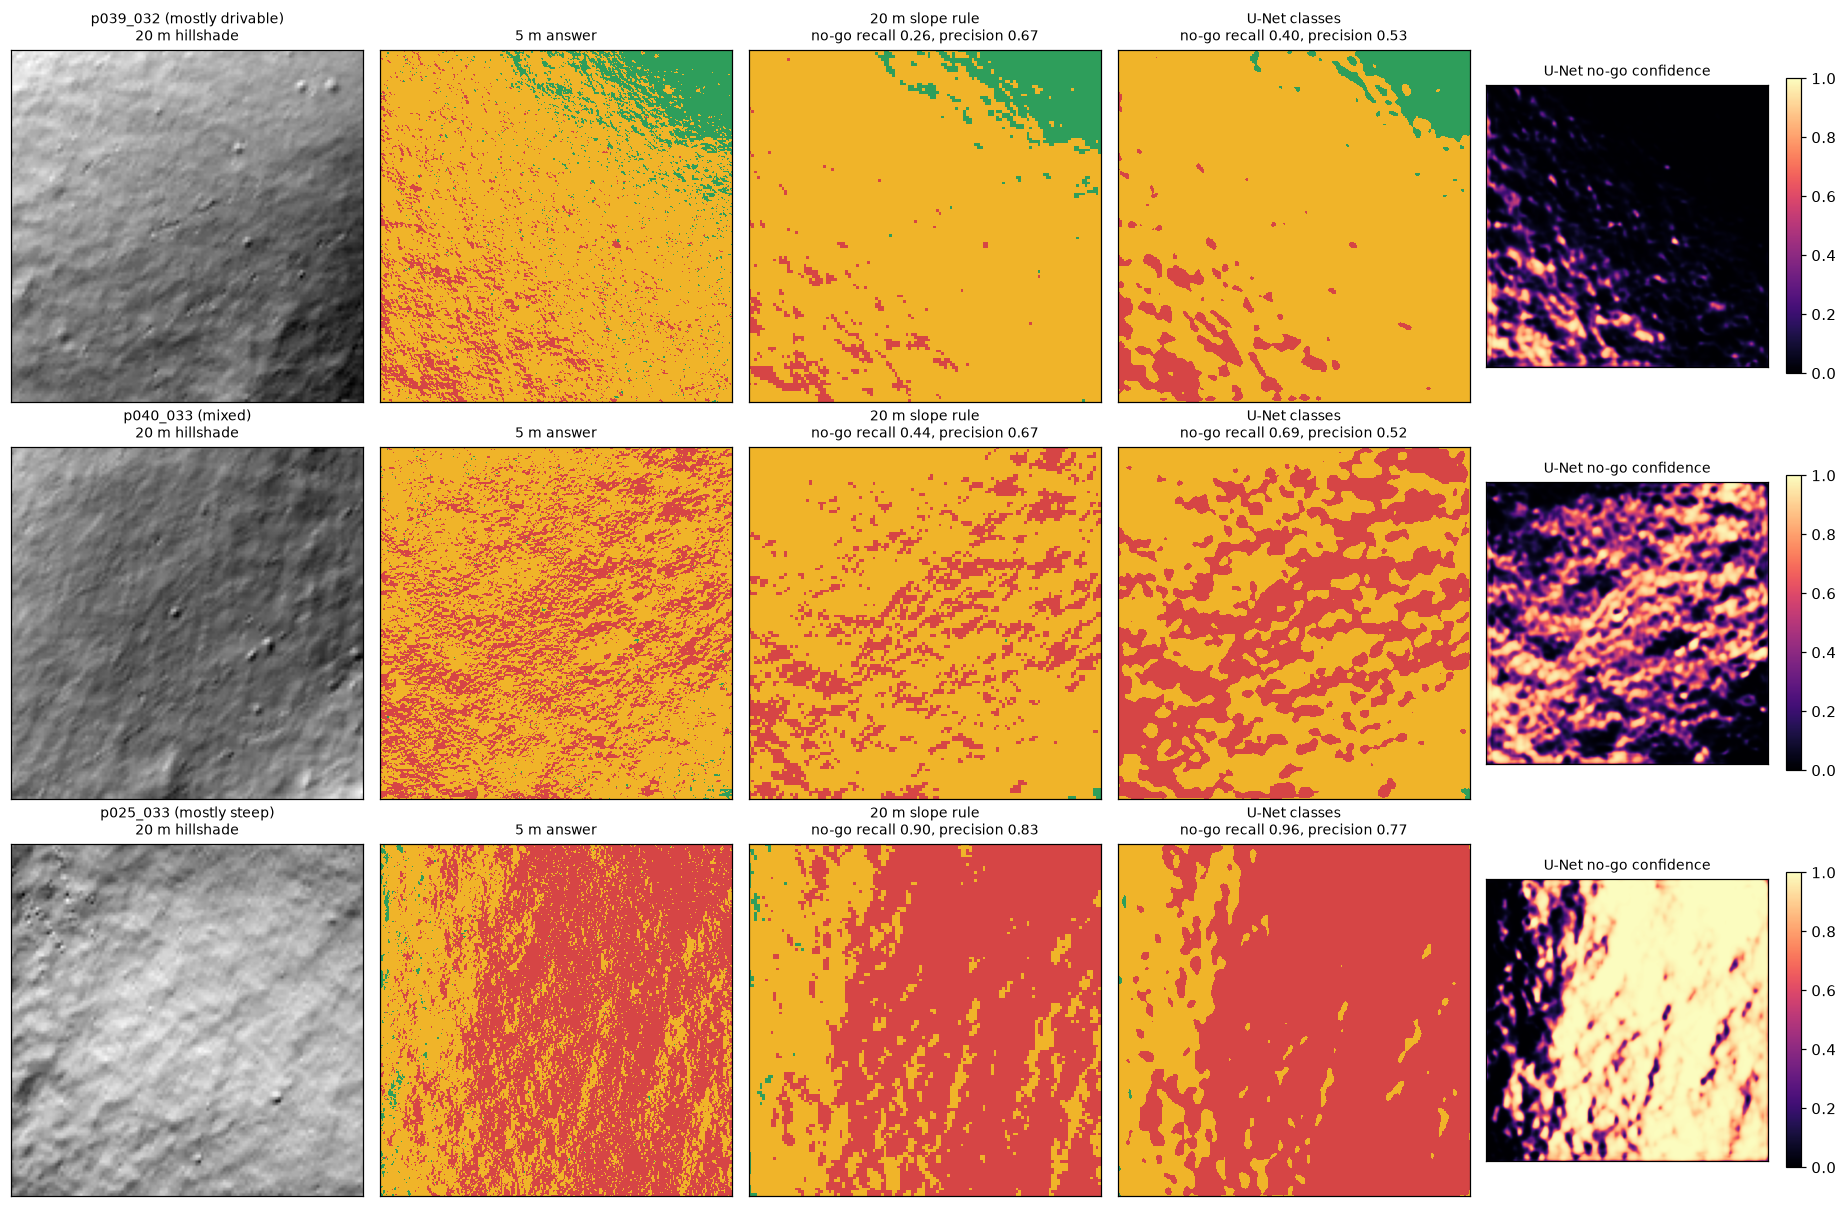

In [12]:
picks = [test[test.terrain == t].sort_values("fn").iloc[-1] for t in TERRAINS if (test.terrain == t).any()]
if picks:
    loaded = [load_patch(p.id) for p in picks]
    prob, cls = predict([l[0] for l in loaded])
    fig, axes = plt.subplots(len(picks), 5, figsize=(17, 3.7 * len(picks)), squeeze=False)
    for k, (p, (x, y, real)) in enumerate(zip(picks, loaded)):
        ax = axes[k]
        rule = np.full(y.shape, NODATA, np.uint8)
        s20 = up4(x[1]); ok = np.isfinite(s20)
        rule[ok] = np.where(s20[ok] >= NOGO_MIN_DEG, 2, np.where(s20[ok] >= SAFE_MAX_DEG, 1, 0))
        ax[0].imshow(x[3], cmap="gray"); ax[0].set_title(f"{p.id} ({p.terrain})\n20 m hillshade", fontsize=9)
        for a, c, t in ((ax[1], y, "5 m answer"), (ax[2], rule, "20 m slope rule"), (ax[3], cls[k], "U-Net classes")):
            a.imshow(np.ma.masked_equal(c, NODATA), cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5, interpolation="nearest")
            r_, p_, _ = prf(int(((c == 2) & (y == 2)).sum()), int(((c == 2) & (y != 2) & (y != NODATA)).sum()),
                            int(((c != 2) & (y == 2)).sum()))
            a.set_title(t if c is y else f"{t}\nno-go recall {r_:.2f}, precision {p_:.2f}", fontsize=9)
        im = ax[4].imshow(prob[k], cmap="magma", vmin=0, vmax=1); plt.colorbar(im, ax=ax[4], shrink=0.8)
        ax[4].set_title("U-Net no-go confidence", fontsize=9)
        for a in ax: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.savefig(FIG / "M3_example_patches.png", dpi=150); plt.show()

## F · Save the numbers

In [13]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 5)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o

summary = clean({
    "settings": {
        "safe_max_deg": {"value": SAFE_MAX_DEG, "label": "sourced: NASA VIPER rover page"},
        "nogo_min_deg": {"value": NOGO_MIN_DEG, "label": "placeholder: project plan"},
        "min_blob_px": {"value": MIN_BLOB_PX, "label": "placeholder: rover-scale hazard size"},
        "win_margin": {"value": WIN_MARGIN, "label": "placeholder"},
        "strata": [list(s) for s in STRATA],
        "model": dict(config, used_weights=str(used_weights), params_m=round(n_params / 1e6, 2)),
        "quick_test_mode": QUICK,
    },
    "measured": {
        "A_label_check": A_tab.reset_index(names="terrain").to_dict(orient="records"),
        "C_training": {"best_round": best_epoch, "rounds_run": int(len(H)),
                       "best_val_ap_drivable": best, "minutes": float(H.minutes.sum()),
                       "history": H.to_dict(orient="records")},
        "D_test_scores": D.to_dict(orient="records"),
        "verdict": VERDICT,
    },
    "model_checkpoint": str(ckpt_best),
    "data_citations": ["Barker et al. 2023, PSJ 4, 183, doi:10.3847/PSJ/acf3e1",
                       "Barker et al. 2021, PSS 203, 105119, doi:10.1016/j.pss.2020.105119"],
})
(RESULTS / "m3_summary.json").write_text(json.dumps(summary, indent=2))
print("Wrote", RESULTS / "m3_summary.json")
print("Verdict:", VERDICT)

Wrote results/m3_summary.json
Verdict: U-Net does not clearly beat the tuned slope rule. Per the plan, the proposal uses the rule-based map (Dec 20 checkpoint).


## What to send back

- **Section A table:** the isolated-speck share and the shot vs filled-in rates for mostly drivable ground.
- **Section D "mostly drivable" rows**, both label versions, all pixels and LOLA-shot pixels.
- **The verdict line** and the PR-curve figure.

**Next:** if the U-Net wins, notebook 04 runs it over the whole 80–90°S pole (sliding windows). If it doesn't, notebook 04 builds the rule-based map instead, and the route planner (05) works the same either way.